#### Import & Setup

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Available devices: {tf.config.list_physical_devices()}")

TensorFlow version: 2.21.0
NumPy version: 2.4.6
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


# 1. TensorFlow Tensors

A tensor is the fundamental data structure in TensorFlow.

It generalises scalars, vectors and matrices to arbitrary dimensions.
Each tensor has:
- Shape
- Data type
- Rank (number of dimensions)

In [2]:
# Scalar
scalar = tf.constant(5)

# Vector
vector = tf.constant([1, 2, 3])

# Matrix
matrix = tf.constant([
    [1, 2, 3],
    [4, 5, 6]
])

# 3D Tensor
tensor_3d = tf.constant([
    [[1, 2], [3, 4]],
    [[5, 6], [7, 8]]
])

for name, tensor in [
    ("Scalar", scalar),
    ("Vector", vector),
    ("Matrix", matrix),
    ("3D Tensor", tensor_3d)
]:
    print(f"{name}:")
    print("Value:\n", tensor.numpy())
    print("Shape:", tensor.shape)
    print("Rank:", tf.rank(tensor).numpy())
    print("-" * 40)

Scalar:
Value:
 5
Shape: ()
Rank: 0
----------------------------------------
Vector:
Value:
 [1 2 3]
Shape: (3,)
Rank: 1
----------------------------------------
Matrix:
Value:
 [[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Rank: 2
----------------------------------------
3D Tensor:
Value:
 [[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]
Shape: (2, 2, 2)
Rank: 3
----------------------------------------


# 2. Tensor Operations

TensorFlow supports mathematical operations directly on tensors.

We will explore:
- Element-wise operations
- Matrix multiplication
- Reshaping
- Transposition
- Reductions

In [3]:
# Two matrices
A = tf.constant([
    [1.0, 2.0],
    [3.0, 4.0]
])

B = tf.constant([
    [5.0, 6.0],
    [7.0, 8.0]
])

# Element-wise addition
addition = tf.add(A, B)

# Element-wise multiplication
multiplication = tf.multiply(A, B)

# Matrix multiplication
matrix_product = tf.matmul(A, B)

# Transpose
transpose = tf.transpose(A)

# Reduction
mean_value = tf.reduce_mean(A)

print("Addition:\n", addition.numpy())
print("\nElement-wise multiplication:\n", multiplication.numpy())
print("\nMatrix multiplication:\n", matrix_product.numpy())
print("\nTranspose:\n", transpose.numpy())
print("\nMean:", mean_value.numpy())

Addition:
 [[ 6.  8.]
 [10. 12.]]

Element-wise multiplication:
 [[ 5. 12.]
 [21. 32.]]

Matrix multiplication:
 [[19. 22.]
 [43. 50.]]

Transpose:
 [[1. 3.]
 [2. 4.]]

Mean: 2.5


# 3. Building a Neural Network with Keras

We will construct a simple feed-forward neural network using
the Keras Sequential API.

The architecture will contain:
- Input layer: 12 features
- Hidden layer: 64 neurons with ReLU activation
- Hidden layer: 32 neurons with ReLU activation
- Output layer: 1 neuron with sigmoid activation

In [4]:
from tensorflow import keras
from tensorflow.keras import layers

# Define the architecture
model = keras.Sequential([
    keras.Input(shape=(12,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Inspect the architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

# 4. Loss Functions and Optimisation

For binary classification, we use Binary Cross-Entropy.

The optimiser adjusts model parameters to minimise
the loss function.

We will compare the initial predictions and loss
before and after training.

In [5]:
# Configure the model for binary classification

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

model.optimizer.get_config()

{'name': 'adam',
 'learning_rate': 0.0010000000474974513,
 'weight_decay': None,
 'clipnorm': None,
 'global_clipnorm': None,
 'clipvalue': None,
 'use_ema': False,
 'ema_momentum': 0.99,
 'ema_overwrite_frequency': None,
 'loss_scale_factor': None,
 'gradient_accumulation_steps': None,
 'beta_1': 0.9,
 'beta_2': 0.999,
 'epsilon': 1e-07,
 'amsgrad': False}

# 5. Training a Neural Network

We generate synthetic binary classification data.

The objective is to train the network to estimate
the probability of belonging to the positive class.

In [6]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Generate synthetic dataset
X, y = make_classification(
    n_samples=5000,
    n_features=12,
    n_informative=8,
    n_redundant=2,
    n_classes=2,
    weights=[0.85, 0.15],
    random_state=42
)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardisation
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training default rate:", y_train.mean())
print("Testing default rate:", y_test.mean())

Training shape: (4000, 12)
Testing shape: (1000, 12)
Training default rate: 0.15325
Testing default rate: 0.153


In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8328 - auc: 0.7334 - loss: 0.4048 - val_accuracy: 0.9125 - val_auc: 0.9059 - val_loss: 0.2565
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 566us/step - accuracy: 0.9269 - auc: 0.9316 - loss: 0.2198 - val_accuracy: 0.9400 - val_auc: 0.9421 - val_loss: 0.1828
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 572us/step - accuracy: 0.9469 - auc: 0.9583 - loss: 0.1651 - val_accuracy: 0.9463 - val_auc: 0.9579 - val_loss: 0.1559
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 547us/step - accuracy: 0.9547 - auc: 0.9718 - loss: 0.1355 - val_accuracy: 0.9513 - val_auc: 0.9675 - val_loss: 0.1376
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 615us/step - accuracy: 0.9628 - auc: 0.9787 - loss: 0.1165 - val_accuracy: 0.9575 - val_auc: 0.9703 - val_loss: 0.1259
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step - accuracy: 0.9669 - auc: 0.9821 - loss: 0.1036 - val_accuracy: 0.9588 - val_auc: 0.9712 - val_loss: 0.1248
Epoch 7/30
100/100 ━━━━━━━━━━━

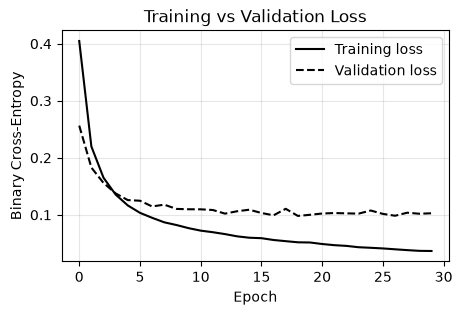

In [11]:
plt.figure(figsize=(5, 3))

plt.plot(history.history["loss"]    , label="Training loss"  , color='black', linestyle='-')
plt.plot(history.history["val_loss"], label="Validation loss", color='black', linestyle='--')

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()